# SEM boundaries · the C-PML, free surfaces and snapshots

Every side of the model is either absorbing (a C-PML layer, `abcn` grid cells thick, added
outside the model) or free (a free surface on the model's edge). This notebook shows both,
with wavefield snapshots:

1. Snapshots: `return_wavefield=True`, `snapshot_times` and the snapshot layout
2. The absorbing layer: no layer, a thin one and the default
3. Free surfaces: `free_surface=True`, edge names, a dict
4. Topography: an elastic free surface over a hill

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM
from sweep.sem.equations import AcousticSEM2DDeformed, ElasticVSSEM2DDeformed
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
dh, n_order, f0, dt = 10.0, 4, 10.0, 0.8e-3
delay = 0.12

## 1. Snapshots

`return_wavefield=True` makes the call return `(record, snapshots)`. `snapshot_times=[...]`
picks the steps (or `snapshot_interval=k`; by default every step is kept). The snapshots are
the field on the grid of the model and its absorbing layer, with the layout of `PropTorch`:

`(nsnap, nfield, nshots, 1, nz + pads, nx + pads)`

where an absorbing side has a pad of `abcn` cells and a free side none, and
`solver.snapshot_fields` names the fields. Snapshots need `impl='eager'`; the CUDA kernels keep
no intermediate wavefield. The acoustic runs below use `AcousticSEM2DDeformed`, whose field is
the pressure. Two helpers, one that crops the pads off and one that plots:

In [2]:
def crop(snap, solver):
    """(..., nz + pads, nx + pads) -> (..., nz, nx): drop the absorbing layer."""
    a = solver.abcn
    free = set(solver.free_surface)
    t = 0 if 'top' in free else a
    l = 0 if 'left' in free else a
    nz, nx = solver.shape
    return snap[..., t:t + nz, l:l + nx]


def show(ax, img, title, src=None, lim=None):
    v = img[np.isfinite(img) & (img != 0)]
    lim = np.percentile(np.abs(v), 99) if lim is None else lim
    nz, nx = img.shape
    ax.imshow(img, cmap='seismic', vmin=-lim, vmax=lim,
              extent=[0, (nx - 1) * dh, (nz - 1) * dh, 0])
    if src is not None:
        ax.plot(src[0] * dh, src[1] * dh, 'k*', ms=8)
    ax.set_title(title, fontsize=10); ax.set_xlabel('x (m)')

## 2. The absorbing layer

A homogeneous acoustic model, the source near the left side, and three solvers that differ
only in `abcn`: `0`, no layer (a side with neither a layer nor a free surface is rigid and
reflects everything); `8` cells, two elements; and the default, `abcn=None`, ten elements
(40 cells). The snapshot is 0.45 s after the source's peak, when the wave has reached the sides
and come back.

In [3]:
shape = (81, 121)                             # 800 m x 1200 m
vp = torch.full(shape, 2000.0, device=device)
nt = 800
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
src = np.array([[40, 40]])
rec = np.array([[[100, 40]]])                 # one receiver to the right
step = int(round((delay + 0.45) / dt))

imgs = {}
for abcn in (0, 8, None):
    solver = PropSEM(AcousticSEM2DDeformed, shape=shape, dh=dh, dt=dt,
                     n_order=n_order, abcn=abcn, f_dominant=f0, device=device)
    with torch.no_grad():
        _, snaps = solver(wavelet, src, rec, models=[vp],
                          return_wavefield=True, snapshot_times=[step])
    print(f'abcn={solver.abcn:3d}  snapshot {tuple(snaps.shape)}  fields {solver.snapshot_fields}')
    imgs[solver.abcn] = crop(snaps[0, 0, 0, 0].numpy(), solver)

sweep: torch.compile is compiling the AcousticSEM2DDeformed step for a 81x121 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


abcn=  0  snapshot (1, 1, 1, 1, 81, 121)  fields ['u']


sweep: torch.compile is compiling the AcousticSEM2DDeformed step for a 81x121 grid


abcn=  8  snapshot (1, 1, 1, 1, 97, 137)  fields ['u']


sweep: torch.compile is compiling the AcousticSEM2DDeformed step for a 81x121 grid


abcn= 40  snapshot (1, 1, 1, 1, 161, 201)  fields ['u']


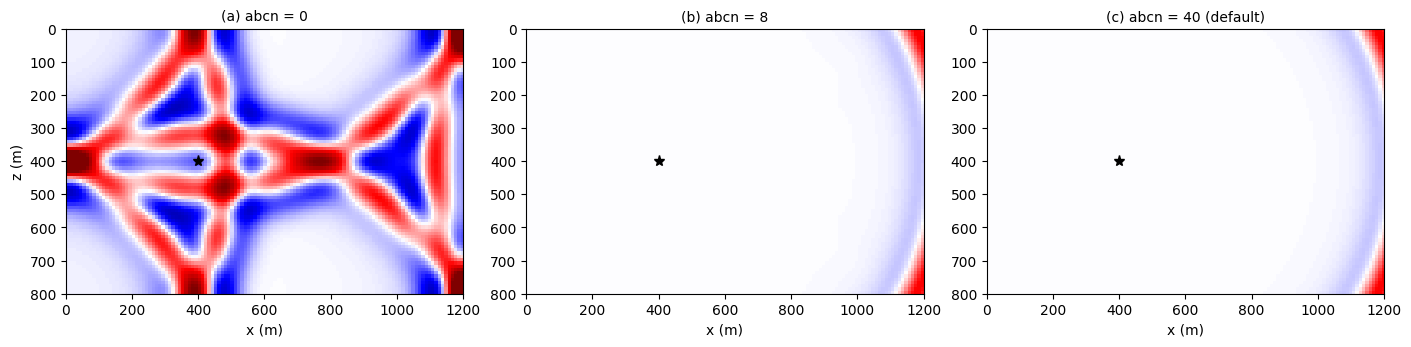

In [4]:
# one colour scale for the three, so the reflections compare directly
lim = np.percentile(np.abs(imgs[0][imgs[0] != 0]), 99)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), constrained_layout=True)
for ax, lab, (abcn, img) in zip(axes, 'abc', imgs.items()):
    show(ax, img, f'({lab}) abcn = {abcn}' + (' (default)' if abcn == 40 else ''), src[0], lim)
axes[0].set_ylabel('z (m)')
plt.show()

With no layer every side reflects; on the same colour scale two elements of C-PML leave
nothing visible, and the default ten elements leave a margin for grazing angles and lower
frequencies. The layer is part of the mesh and costs compute. `abcn` is in grid cells, a
multiple of `n_order`, and the same on every absorbing side.

## 3. Free surfaces

`free_surface` takes the same forms as on `PropTorch`: `True` for the top; edge names,
`'top'` or `['top', 'left']` (`top`, `bottom`, `left`, `right`, and in 3-D `front`, `back`);
or a dict `{'top': True, 'left': True}`. A free side has no absorbing layer. For an acoustic
equation it is a pressure-release surface: the reflection has the opposite polarity, where the
rigid side above had the same.

sweep: torch.compile is compiling the AcousticSEM2DDeformed step for a 81x121 grid


free_surface=True               -> ('top',), snapshot (1, 1, 1, 1, 121, 201)


sweep: torch.compile is compiling the AcousticSEM2DDeformed step for a 81x121 grid


free_surface=['top', 'left']    -> ('top', 'left'), snapshot (1, 1, 1, 1, 121, 161)


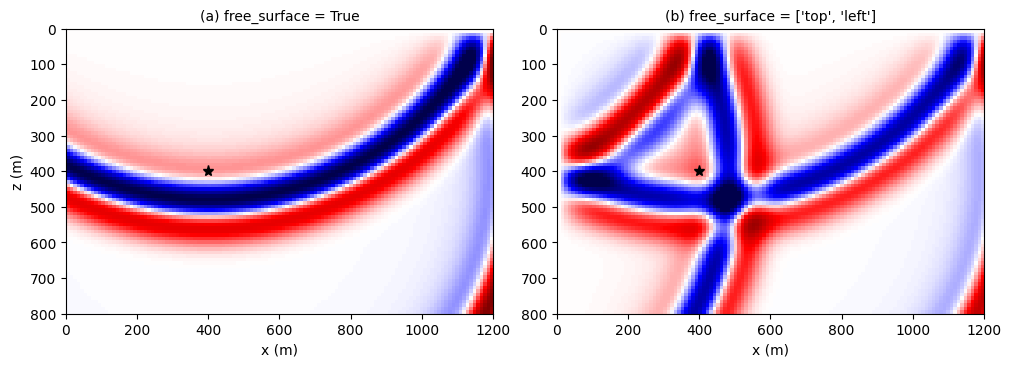

In [5]:
imgs = {}
for fs in (True, ['top', 'left']):
    solver = PropSEM(AcousticSEM2DDeformed, shape=shape, dh=dh, dt=dt,
                     n_order=n_order, free_surface=fs, f_dominant=f0, device=device)
    with torch.no_grad():
        _, snaps = solver(wavelet, src, rec, models=[vp],
                          return_wavefield=True, snapshot_times=[step])
    print(f'free_surface={fs!r:18s} -> {solver.free_surface}, snapshot {tuple(snaps.shape)}')
    imgs[str(fs)] = crop(snaps[0, 0, 0, 0].numpy(), solver)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for ax, lab, (fs, img) in zip(axes, 'ab', imgs.items()):
    show(ax, img, f'({lab}) free_surface = {fs}', src[0])
axes[0].set_ylabel('z (m)')
plt.show()

## 4. Topography

`topography` puts a curved free surface on top, and the mesh follows it
([SEM mesh and time step](../50_sem_mesh_and_time_step/)). An explosion under a 150 m hill in an
elastic half-space, and three snapshots of the vertical particle velocity from the
velocity-stress equation, whose field is the velocity itself. Snapshots of a class with CUDA
kernels need `impl='eager'`. The snapshot is zero above the surface; it is blanked so that the
air shows white.

sweep: torch.compile is compiling the ElasticVSSEM2DDeformed step for a 101x241 grid


snapshot (3, 1, 1, 1, 141, 321) ['v_z']


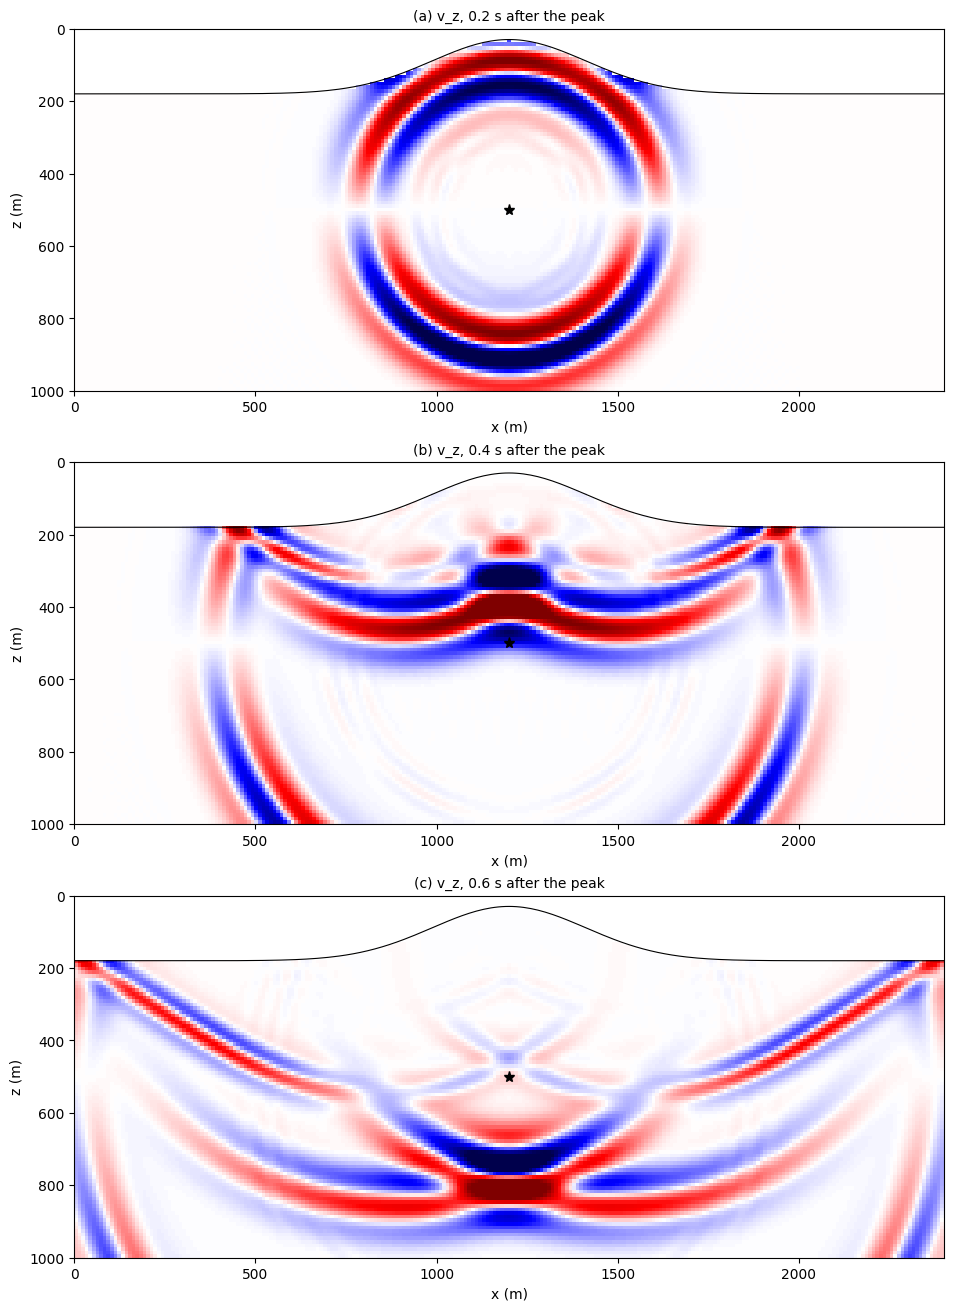

In [6]:
shape = (101, 241)                                       # 1 km x 2.4 km
ix = np.arange(shape[1])
topo = 18.0 - 15.0 * np.exp(-((ix - 120) / 30.0) ** 2)   # surface row: 180 m -> 30 m
vp  = torch.full(shape, 2000.0, device=device)
vs  = torch.full(shape, 1150.0, device=device)
rho = torch.full(shape, 2000.0, device=device)
nt = 1000
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
src = np.array([[120, 50]])                               # 500 m deep, under the crest
rx = np.arange(0, shape[1], 4)
rec = np.stack([rx, np.ceil(topo[rx]) + 1], axis=1)[None]  # one row below the surface
steps = [int(round((delay + s) / dt)) for s in (0.2, 0.4, 0.6)]

solver = PropSEM(ElasticVSSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 topography=topo, f_dominant=f0, source_type=['sxx', 'szz'],
                 receiver_type=['vz'], impl='eager', device=device)
with torch.no_grad():
    seis, snaps = solver(wavelet, src, rec, models=[vp, vs, rho],
                         return_wavefield=True, snapshot_times=steps)
print('snapshot', tuple(snaps.shape), solver.snapshot_fields)

vz = crop(snaps[:, 0, 0, 0].numpy(), solver)              # (3, nz, nx): field v_z
air = np.arange(shape[0])[:, None] < topo[None, :]
vz[:, air] = np.nan
fig, axes = plt.subplots(3, 1, figsize=(12, 13), constrained_layout=True)
for ax, lab, img, s in zip(axes, 'abc', vz, (0.2, 0.4, 0.6)):
    show(ax, img, f'({lab}) v_z, {s:.1f} s after the peak', src[0])
    ax.plot(ix * dh, topo * dh, 'k-', lw=0.8)
    ax.set_ylabel('z (m)')
plt.show()

The P wave reaches the crest first; at the surface it converts into S waves and Rayleigh
waves that travel down the flanks. The receivers here follow the surface one row below it,
which is how a surface spread is placed on topography.

## Summary

| option | meaning |
| --- | --- |
| `abcn` | C-PML width in grid cells on every non-free side, a multiple of `n_order`; `None` = ten elements, `0` = rigid sides |
| `free_surface` | `True` (top), edge names, or `{edge: bool}`; free sides get no layer |
| `topography` | the surface row per column: a curved free surface on top |
| `return_wavefield=True` | `(record, snapshots)`, eager only; `snapshot_times` / `snapshot_interval` pick the steps |

On the velocity-stress solids a C-PML side may not run between two free sides: the solid
between them is a plate, whose Lamb modes grow inside a PML. `PropSEM` refuses such a set-up
and says which side to change.

Next: [SEM gradients · backends and memory strategies](../54_sem_gradients_and_memory/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="53_sem_boundaries_and_snapshots.ipynb" download><code>53_sem_boundaries_and_snapshots.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/53_sem_boundaries_and_snapshots.ipynb">view on GitHub</a></p>